# House Price Prediction using Linear Regression

End-to-end supervised learning pipeline: missing value handling, outlier
removal, feature engineering, feature scaling, model training, and
evaluation using MSE and R².

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from preprocessing import (
    load_data, handle_missing_values, remove_outliers,
    engineer_features, scale_features, ENGINEERED_FEATURES, TARGET
)
from modeling import split_data, train_model, evaluate_model, coefficient_table

sns.set_style('whitegrid')
%matplotlib inline

## 1. Load Data

In [2]:
raw = load_data('../data/housing_data.csv')
print(f"{len(raw)} rows")
print(raw.isnull().sum())
raw.head()

800 rows
HouseID               0
SquareFootage         0
Bedrooms              0
Bathrooms            24
LotSize              32
YearBuilt             0
GarageSpaces         16
DistanceToCity_km     0
SchoolRating         40
Price                 0
dtype: int64


,HouseID,SquareFootage,Bedrooms,Bathrooms,LotSize,YearBuilt,GarageSpaces,DistanceToCity_km,SchoolRating,Price
0,H2000,1801.0,3,2.8,5676.0,2016,2.0,12.8,8.0,419796.0
1,H2001,1994.0,3,3.0,3687.0,1971,1.0,1.0,6.0,467499.0
2,H2002,1622.0,2,2.2,1222.0,1970,1.0,6.8,7.0,283103.0
3,H2003,1221.0,2,2.3,1788.0,1994,0.0,4.7,3.0,291890.0
4,H2004,1504.0,1,1.0,2793.0,2014,1.0,6.9,NaN,342184.0


## 2. Handle Missing Values & Outliers

In [3]:
df = handle_missing_values(raw)
df = remove_outliers(df)
print(f"After cleaning: {len(df)} rows, missing values remaining: {df.isnull().sum().sum()}")

After cleaning: 797 rows, missing values remaining: 0


## 3. Exploratory Data Analysis

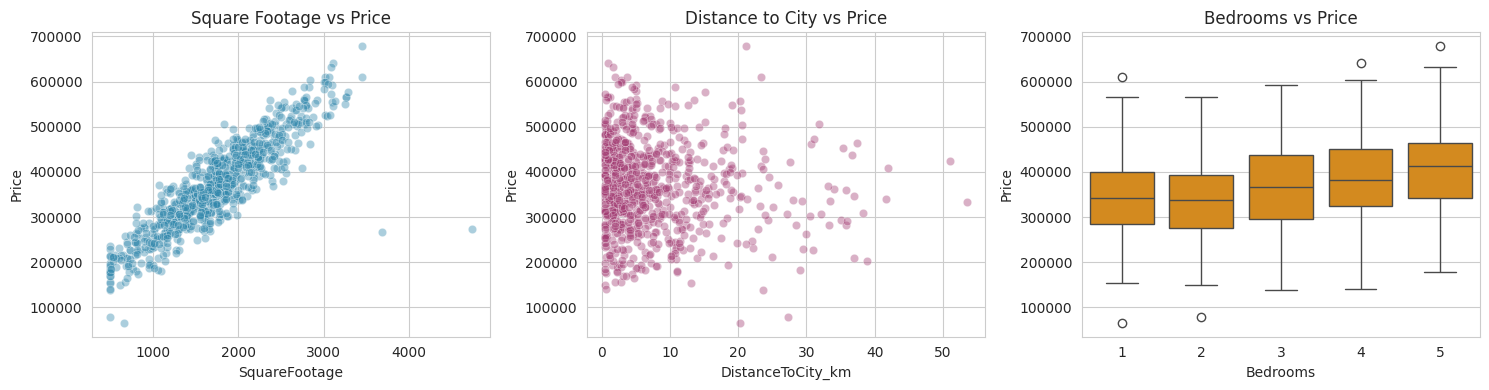

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(data=df, x='SquareFootage', y='Price', ax=axes[0], alpha=0.4, color='#2E86AB')
sns.scatterplot(data=df, x='DistanceToCity_km', y='Price', ax=axes[1], alpha=0.4, color='#A23B72')
sns.boxplot(data=df, x='Bedrooms', y='Price', ax=axes[2], color='#F18F01')
axes[0].set_title('Square Footage vs Price')
axes[1].set_title('Distance to City vs Price')
axes[2].set_title('Bedrooms vs Price')
plt.tight_layout()
plt.show()

## 4. Feature Engineering

In [5]:
df = engineer_features(df)
df[['HouseAge', 'PricePerSqft_proxy', 'TotalRooms']].describe()

,HouseAge,PricePerSqft_proxy,TotalRooms
count,797.000000,797.000000,797.00000
mean,40.224592,1.818775,5.46010
std,21.406299,0.518168,2.41525
min,3.000000,0.391654,2.00000
25%,22.000000,1.457627,3.30000
50%,41.000000,1.817708,5.30000
75%,59.000000,2.138292,7.60000
max,76.000000,5.797405,10.00000


## 5. Feature Scaling

In [6]:
scaled_X, scaler = scale_features(df)
y = df[TARGET]
scaled_X.describe()

,SquareFootage,Bedrooms,Bathrooms,LotSize,GarageSpaces,DistanceToCity_km,SchoolRating,HouseAge,PricePerSqft_proxy,TotalRooms
count,7.970000e+02,7.970000e+02,7.970000e+02,7.970000e+02,7.970000e+02,7.970000e+02,7.970000e+02,7.970000e+02,7.970000e+02,7.970000e+02
mean,1.604739e-16,8.915216e-17,1.459867e-16,-1.337282e-16,2.228804e-17,1.314994e-16,8.023695e-17,-8.803776e-17,1.560163e-17,-4.073139e-16
std,1.000628e+00,1.000628e+00,1.000628e+00,1.000628e+00,1.000628e+00,1.000628e+00,1.000628e+00,1.000628e+00,1.000628e+00,1.000628e+00
min,-2.020619e+00,-1.452800e+00,-1.285978e+00,-1.513973e+00,-1.367803e+00,-8.738329e-01,-1.599115e+00,-1.740047e+00,-2.755897e+00,-1.433505e+00
25%,-6.871231e-01,-7.493483e-01,-9.172010e-01,-7.078297e-01,-4.735133e-01,-6.869782e-01,-8.892877e-01,-8.519005e-01,-6.974083e-01,-8.949206e-01
50%,1.605729e-03,-4.589648e-02,-8.745162e-02,-1.612861e-01,4.207761e-01,-3.381828e-01,-1.794607e-01,3.624609e-02,-2.059389e-03,-6.632892e-02
75%,6.528860e-01,6.575553e-01,8.344921e-01,5.578502e-01,1.315065e+00,3.220371e-01,8.852799e-01,8.776481e-01,6.170162e-01,8.865515e-01
max,4.876438e+00,1.361007e+00,2.401796e+00,4.159569e+00,1.315065e+00,5.728366e+00,1.595107e+00,1.672306e+00,7.683090e+00,1.880862e+00


## 6. Train/Test Split & Model Training

In [7]:
X_train, X_test, y_train, y_test = split_data(scaled_X, y)
model = train_model(X_train, y_train)
print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")

Train size: 637, Test size: 160


## 7. Evaluation: MSE, RMSE, R²

In [8]:
metrics = evaluate_model(model, X_test, y_test)
print(f"MSE:  {metrics['mse']:,.0f}")
print(f"RMSE: {metrics['rmse']:,.0f}")
print(f"R^2:  {metrics['r2']:.3f}")

MSE:  1,813,377,730
RMSE: 42,584
R^2:  0.807


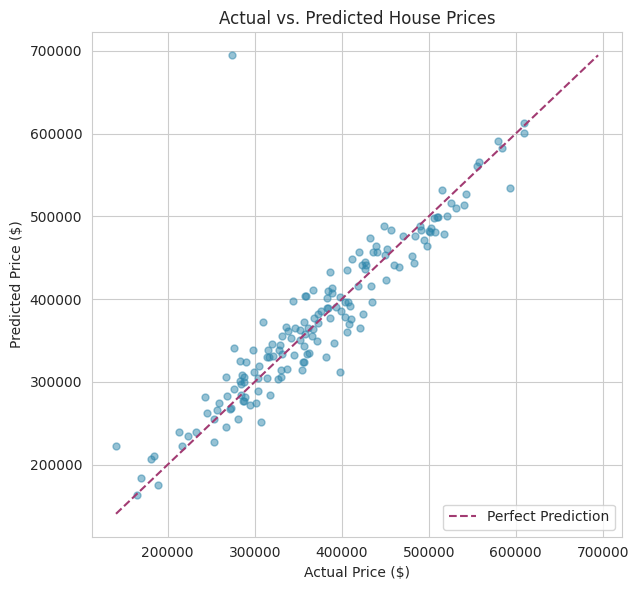

In [9]:
plt.figure(figsize=(6.5, 6))
plt.scatter(y_test, metrics['predictions'], alpha=0.5, color='#2E86AB', s=25)
lims = [min(y_test.min(), metrics['predictions'].min()), max(y_test.max(), metrics['predictions'].max())]
plt.plot(lims, lims, '--', color='#A23B72', label='Perfect Prediction')
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.title('Actual vs. Predicted House Prices')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Feature Importance

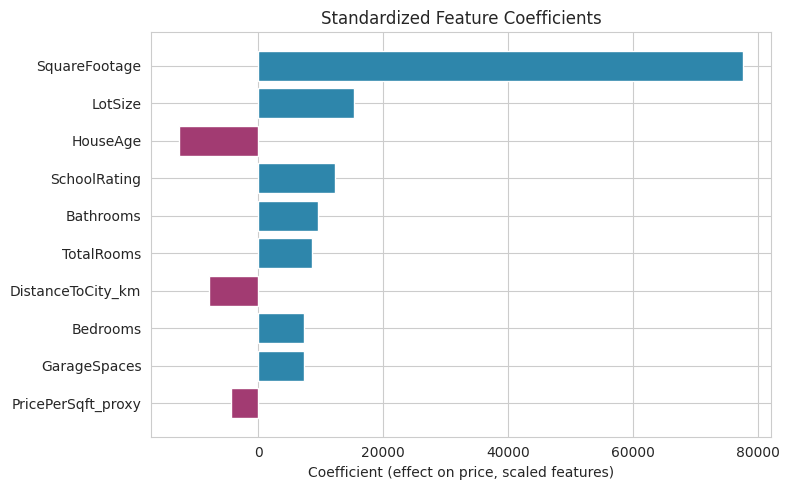

,Feature,Coefficient
0,SquareFootage,77566.795225
1,LotSize,15287.816305
2,HouseAge,-12595.246017
3,SchoolRating,12371.303289
4,Bathrooms,9578.714529
5,TotalRooms,8665.069156
6,DistanceToCity_km,-7910.827081
7,Bedrooms,7404.165166
8,GarageSpaces,7349.724828
9,PricePerSqft_proxy,-4331.133048


In [10]:
coef_df = coefficient_table(model, ENGINEERED_FEATURES)
plt.figure(figsize=(8, 5))
colors = ['#2E86AB' if c > 0 else '#A23B72' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
plt.title('Standardized Feature Coefficients')
plt.xlabel('Coefficient (effect on price, scaled features)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
coef_df

Square footage is the dominant driver of price, followed by lot size and
school rating. House age and distance to city center both reduce price,
consistent with real-world housing market intuition. The R² of ~0.81
indicates the model captures most of the price variance from these
structured features, with the remainder likely explained by factors
like renovation quality and hyperlocal neighborhood effects.